# Assignment 3: SIFT Feature Descriptor and Feature Matching and Homography-Based Image Warping

This notebook has two sections:

1. **SIFT feature descriptor and ratio-distance feature matching**
2. **Image warping via a homography in homogeneous coordinates**

Each section has a worked **Sample code** cell followed by a completed **TODO** solution cell.

### Submission requirements

- Complete every cell labeled **TODO** in the student version.
- Run all cells and submit the executed `.ipynb` file and corresponding `.pdf` file.

## 0. Setup

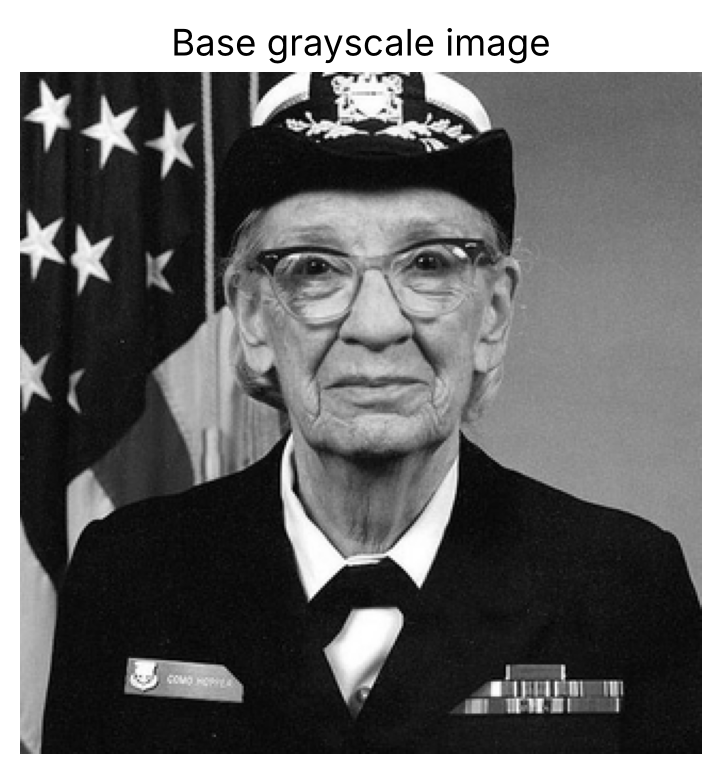

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from matplotlib.cbook import get_sample_data
from scipy.ndimage import (
    affine_transform, gaussian_filter, map_coordinates,
    maximum_filter, rotate, shift, sobel
)

np.random.seed(7)
plt.rcParams.update({'figure.figsize': (12, 5), 'font.size': 11})


def load_grayscale_demo(size=320):
    """Load Matplotlib's bundled photo; use a synthetic fallback if unavailable."""
    try:
        path = get_sample_data('grace_hopper.jpg', asfileobj=False)
        image = Image.open(path).convert('L')
    except Exception:
        image = Image.new('L', (size, size), 35)
        draw = ImageDraw.Draw(image)
        draw.rectangle((25, 25, 145, 135), fill=190, outline=250, width=5)
        draw.ellipse((175, 35, 285, 145), fill=100, outline=245, width=5)
        draw.polygon([(45, 270), (110, 160), (175, 270)], fill=220, outline=40)
        draw.line((200, 190, 290, 280), fill=240, width=7)
        draw.line((290, 190, 200, 280), fill=240, width=7)

    w, h = image.size
    side = min(w, h)
    image = image.crop(((w-side)//2, (h-side)//2, (w+side)//2, (h+side)//2))
    image = image.resize((size, size), Image.Resampling.LANCZOS)
    return np.asarray(image, dtype=np.float64) / 255.0


def show_images(images, titles, cols=None):
    cols = cols or len(images)
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows), squeeze=False)
    for ax, im, title in zip(axes.ravel(), images, titles):
        ax.imshow(im, cmap='gray', vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis('off')
    for ax in axes.ravel()[len(images):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


image = load_grayscale_demo()
show_images([image], ['Base grayscale image'])

## 1. SIFT feature descriptor and ratio-distance feature matching

For each feature descriptor $f_1$, let $d_1$ and $d_2$ be its distances to the nearest and second-nearest descriptors in the other image. Lowe's ratio is

$$r=\frac{d_1}{d_2}.$$

A small ratio indicates that the nearest match is substantially better than the second-best candidate.

### 1.1 Shared SIFT and matching functions

In [2]:
def detect_harris_points(image, max_points=180, sigma=1.4, min_distance=10):
    """Return Harris keypoints as an N x 2 array in (row, column) order."""
    smooth = gaussian_filter(image, sigma)
    gx = sobel(smooth, axis=1, mode='reflect') / 8.0
    gy = sobel(smooth, axis=0, mode='reflect') / 8.0
    a = gaussian_filter(gx*gx, 1.5)
    b = gaussian_filter(gx*gy, 1.5)
    c = gaussian_filter(gy*gy, 1.5)
    response = (a*c - b*b) - 0.04*(a+c)**2

    local_max = response == maximum_filter(response, size=2*min_distance+1)
    border = 14
    local_max[:border] = local_max[-border:] = False
    local_max[:, :border] = local_max[:, -border:] = False
    candidates = np.argwhere(local_max & (response > 0.01*response.max()))
    if len(candidates) == 0:
        return np.empty((0, 2), dtype=int)
    order = np.argsort(response[candidates[:, 0], candidates[:, 1]])[::-1]
    return candidates[order[:max_points]]


def dominant_orientation(gx, gy, row, col, radius=8, bins=36):
    offsets = np.arange(-radius, radius+1)
    dy, dx = np.meshgrid(offsets, offsets, indexing='ij')
    rr, cc = row + dy, col + dx
    mag = np.hypot(gx[rr, cc], gy[rr, cc])
    ang = np.mod(np.arctan2(gy[rr, cc], gx[rr, cc]), 2*np.pi)
    weight = np.exp(-(dx**2 + dy**2)/(2*(0.6*radius)**2))
    idx = np.floor(ang/(2*np.pi)*bins).astype(int) % bins
    hist = np.zeros(bins)
    np.add.at(hist, idx.ravel(), (mag*weight).ravel())
    return (np.argmax(hist)+0.5)*(2*np.pi/bins)


def sift_descriptor(image, point_rc, patch_size=16, cells=4, bins=8):
    """Educational orientation-normalized 128-D SIFT descriptor."""
    smoothed = gaussian_filter(image, 1.0, mode='reflect')
    gx = sobel(smoothed, axis=1, mode='reflect') / 8.0
    gy = sobel(smoothed, axis=0, mode='reflect') / 8.0
    row, col = map(int, point_rc)
    theta = dominant_orientation(gx, gy, row, col)

    q = np.arange(patch_size) - (patch_size-1)/2
    v, u = np.meshgrid(q, q, indexing='ij')
    cosine, sine = np.cos(theta), np.sin(theta)
    source_x = col + cosine*u - sine*v
    source_y = row + sine*u + cosine*v
    sample_gx = map_coordinates(gx, [source_y, source_x], order=1, mode='reflect')
    sample_gy = map_coordinates(gy, [source_y, source_x], order=1, mode='reflect')
    magnitude = np.hypot(sample_gx, sample_gy)
    angle = np.mod(np.arctan2(sample_gy, sample_gx)-theta, 2*np.pi)
    spatial_weight = np.exp(-(u*u+v*v)/(2*(0.5*patch_size)**2))

    cell_size = patch_size//cells
    descriptor = []
    for r in range(cells):
        for c in range(cells):
            sy = slice(r*cell_size, (r+1)*cell_size)
            sx = slice(c*cell_size, (c+1)*cell_size)
            idx = np.floor(angle[sy, sx]/(2*np.pi)*bins).astype(int) % bins
            hist = np.zeros(bins)
            np.add.at(hist, idx.ravel(), (magnitude*spatial_weight)[sy, sx].ravel())
            descriptor.extend(hist)

    descriptor = np.asarray(descriptor, dtype=float)
    descriptor /= np.linalg.norm(descriptor) + 1e-12
    descriptor = np.minimum(descriptor, 0.2)
    descriptor /= np.linalg.norm(descriptor) + 1e-12
    return descriptor


def compute_sift_descriptors(image, points):
    if len(points) == 0:
        return np.empty((0, 128))
    return np.vstack([sift_descriptor(image, point) for point in points])


def ratio_match(descriptors1, descriptors2, ratio_threshold=0.75):
    """Return (query index, train index, ratio) after Lowe's ratio test."""
    if len(descriptors1) == 0 or len(descriptors2) < 2:
        return np.empty((0, 3))
    distances = np.linalg.norm(descriptors1[:, None, :] - descriptors2[None, :, :], axis=2)
    order = np.argsort(distances, axis=1)
    d1 = distances[np.arange(len(descriptors1)), order[:, 0]]
    d2 = distances[np.arange(len(descriptors1)), order[:, 1]]
    ratios = d1/(d2+1e-12)
    keep = np.flatnonzero(ratios < ratio_threshold)
    return np.column_stack([keep, order[keep, 0], ratios[keep]])


def plot_matches(image1, image2, points1, points2, matches, title, max_lines=45):
    canvas = np.hstack([image1, image2])
    width1 = image1.shape[1]
    plt.figure(figsize=(13, 6))
    plt.imshow(canvas, cmap='gray', vmin=0, vmax=1)
    for q, t, ratio in matches[:max_lines]:
        q, t = int(q), int(t)
        y1, x1 = points1[q]
        y2, x2 = points2[t]
        plt.plot([x1, x2+width1], [y1, y2], linewidth=0.8, alpha=0.75)
        plt.scatter([x1, x2+width1], [y1, y2], s=10)
    plt.axvline(width1, color='white', linewidth=1)
    plt.title(title)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

### 1.2 Sample code

Image 1 keypoints: 52
Image 2 keypoints: 50
Descriptor dimension: 128
Accepted ratio-test matches: 30


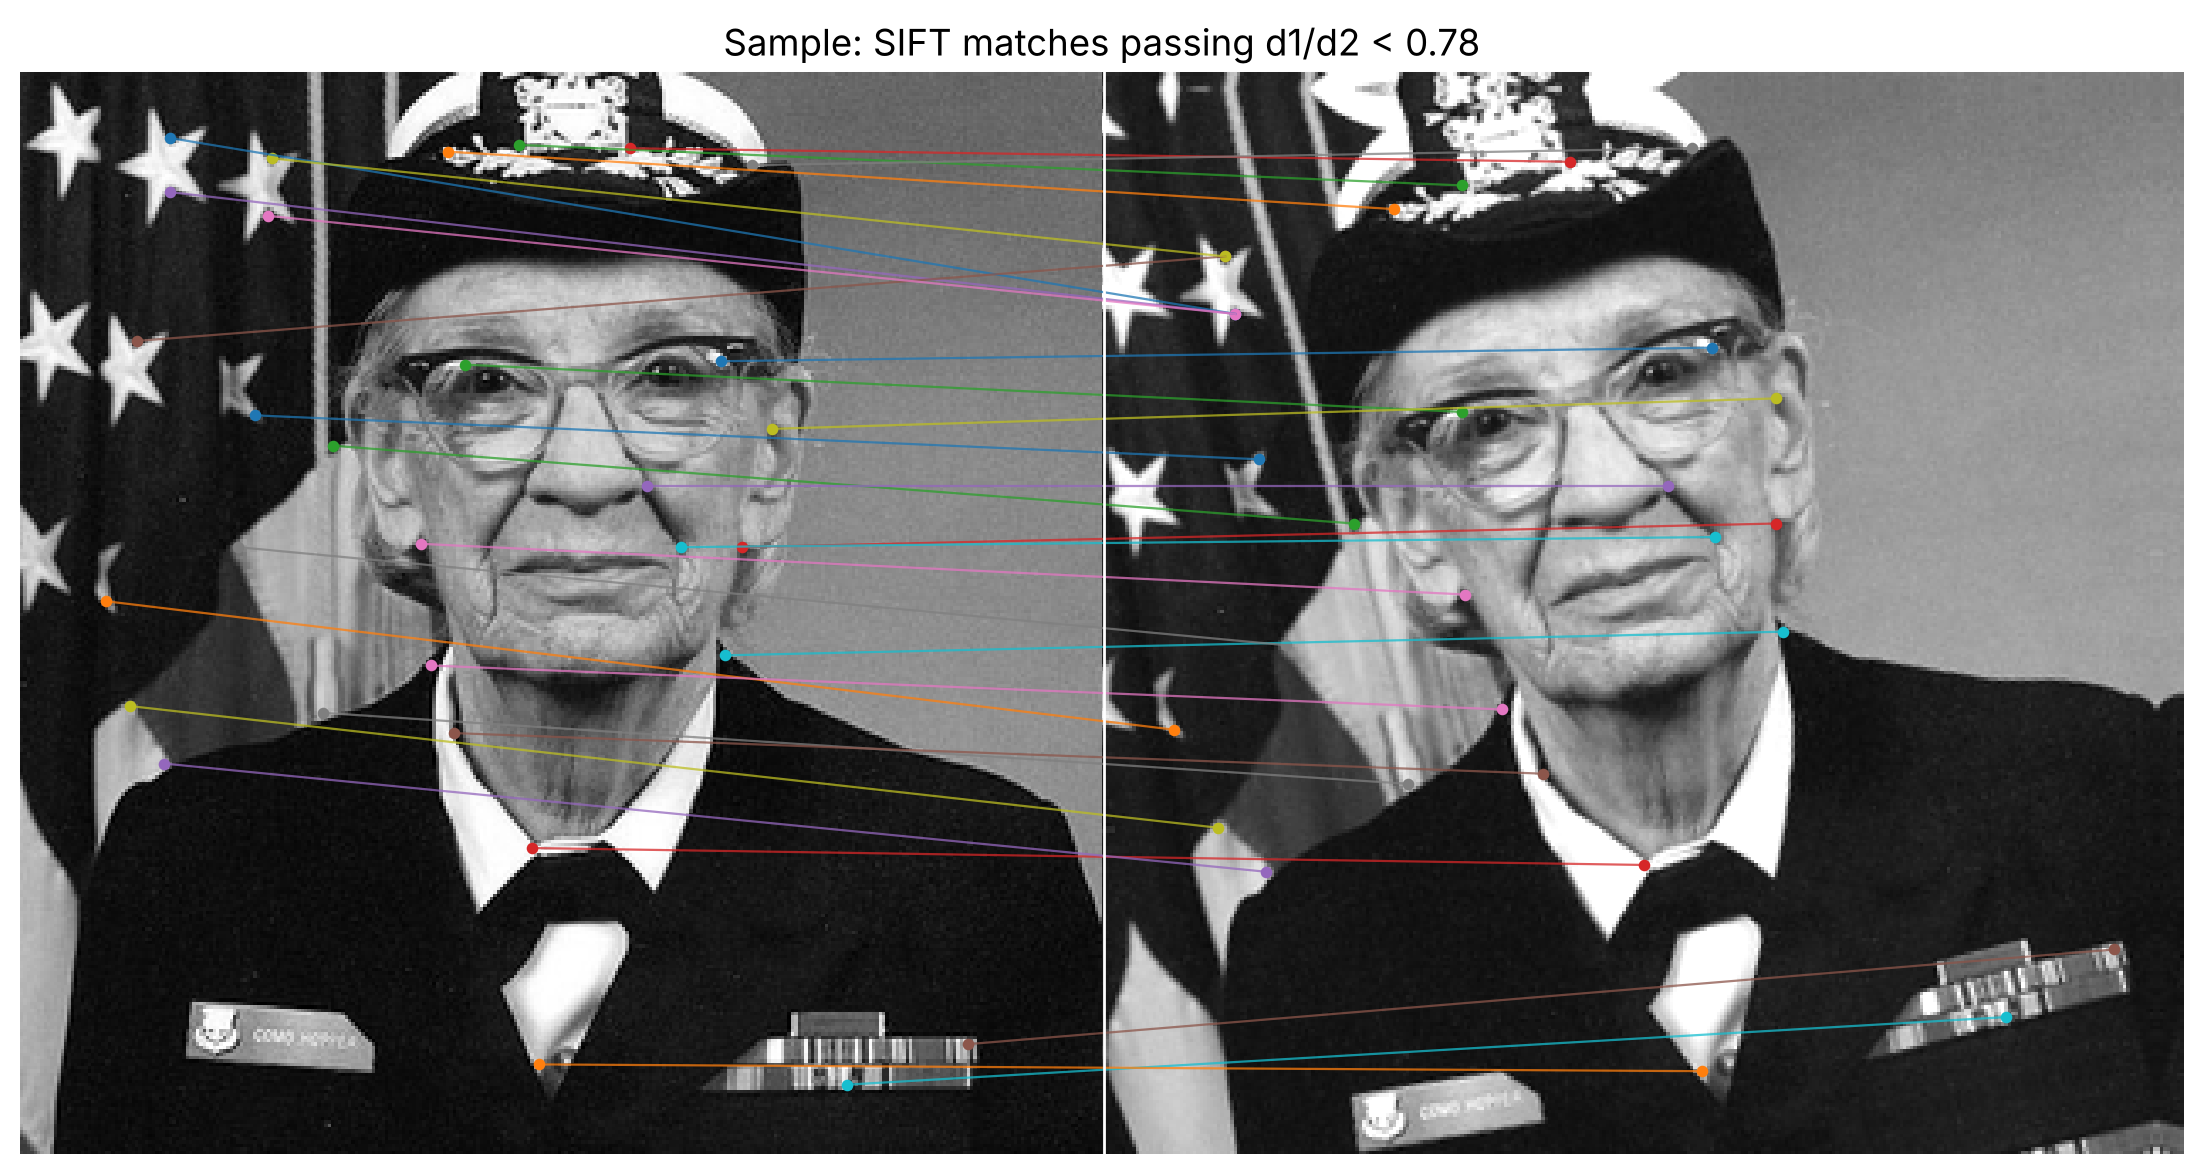

In [3]:
# SAMPLE CODE: create a related image, extract SIFT descriptors, and apply ratio matching.
sample_image2 = rotate(image, angle=14, reshape=False, order=1, mode='reflect')
sample_image2 = shift(sample_image2, shift=(5, -8), order=1, mode='reflect')
sample_image2 = np.clip(1.08*sample_image2 + 0.02, 0, 1)

sample_points1 = detect_harris_points(image)
sample_points2 = detect_harris_points(sample_image2)
sample_desc1 = compute_sift_descriptors(image, sample_points1)
sample_desc2 = compute_sift_descriptors(sample_image2, sample_points2)
sample_matches = ratio_match(sample_desc1, sample_desc2, ratio_threshold=0.78)

print('Image 1 keypoints:', len(sample_points1))
print('Image 2 keypoints:', len(sample_points2))
print('Descriptor dimension:', sample_desc1.shape[1])
print('Accepted ratio-test matches:', len(sample_matches))
plot_matches(image, sample_image2, sample_points1, sample_points2, sample_matches,
             'Sample: SIFT matches passing d1/d2 < 0.78')

### 1.3 TODO: SIFT and ratio matching

Image 1 keypoints: 52
Image 2 keypoints: 50
Descriptor dimension: 128
Accepted ratio-test matches: 33


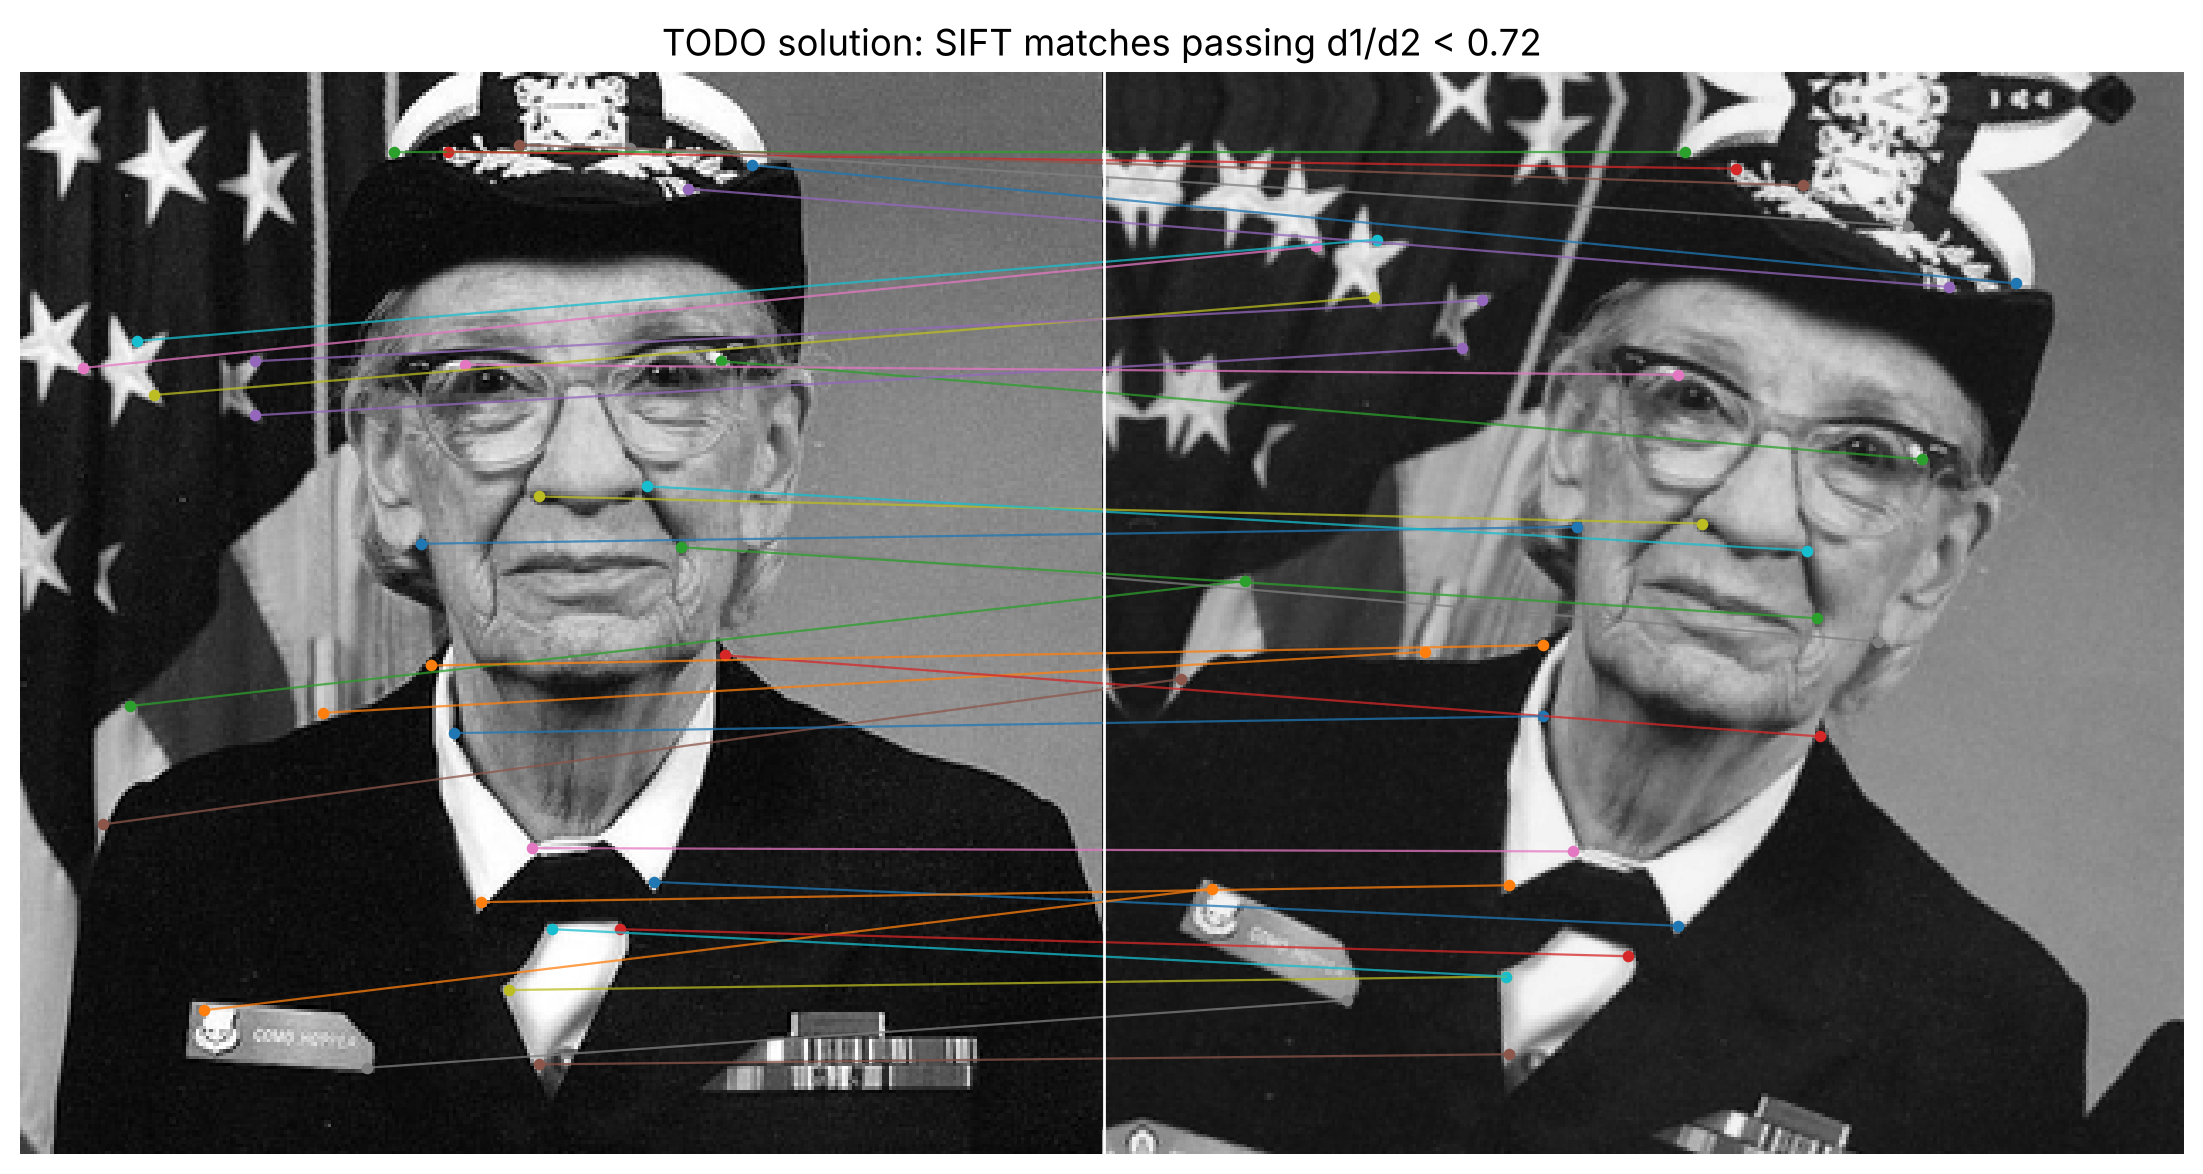

In [4]:
# TODO 1: Create a new transformed image using angle=-20 degrees and shift=(8, 12).
student_image2 = rotate(image, angle=-20, reshape=False, order=1, mode='reflect')
student_image2 = shift(student_image2, shift=(8, 12), order=1, mode='reflect')
student_image2 = np.clip(0.92*student_image2 + 0.04, 0, 1)

# TODO 2: Detect Harris points and compute 128-D SIFT descriptors for both images.
student_points1 = detect_harris_points(image)
student_points2 = detect_harris_points(student_image2)
student_desc1 = compute_sift_descriptors(image, student_points1)
student_desc2 = compute_sift_descriptors(student_image2, student_points2)

# TODO 3: Apply ratio matching using ratio_threshold=0.72.
student_matches = ratio_match(student_desc1, student_desc2, ratio_threshold=0.72)

print('Image 1 keypoints:', len(student_points1))
print('Image 2 keypoints:', len(student_points2))
print('Descriptor dimension:', student_desc1.shape[1])
print('Accepted ratio-test matches:', len(student_matches))
plot_matches(image, student_image2, student_points1, student_points2, student_matches,
             'TODO solution: SIFT matches passing d1/d2 < 0.72')

## 2. Image warping via a homography in homogeneous coordinates

A homography maps a source point $\mathbf p=[x,y,1]^T$ to

$$\tilde{\mathbf p}'=H\mathbf p,\qquad
(x',y')=\left(\frac{\tilde x'}{\tilde w'},\frac{\tilde y'}{\tilde w'}\right).$$

The notebook estimates $H$ with the Direct Linear Transform (DLT) and uses inverse warping with bilinear interpolation.

### 2.1 Shared homography functions

In [5]:
def estimate_homography_dlt(source_xy, destination_xy):
    """Estimate H from at least four point pairs using the DLT algorithm."""
    source_xy = np.asarray(source_xy, dtype=float)
    destination_xy = np.asarray(destination_xy, dtype=float)
    if source_xy.shape != destination_xy.shape or source_xy.shape[0] < 4:
        raise ValueError('Need at least four corresponding 2D point pairs.')

    rows = []
    for (x, y), (u, v) in zip(source_xy, destination_xy):
        rows.append([-x, -y, -1, 0, 0, 0, u*x, u*y, u])
        rows.append([0, 0, 0, -x, -y, -1, v*x, v*y, v])
    _, _, vt = np.linalg.svd(np.asarray(rows))
    H = vt[-1].reshape(3, 3)
    return H/H[2, 2]


def transform_points_homogeneous(points_xy, H):
    points_xy = np.asarray(points_xy, dtype=float)
    homogeneous = np.column_stack([points_xy, np.ones(len(points_xy))])
    mapped_h = (H @ homogeneous.T).T
    return mapped_h[:, :2]/mapped_h[:, 2:3]


def forward_warp_homography(image, H, output_shape=None):
    """Forward-warp every input pixel and bilinearly splat it into the output."""
    output_shape = output_shape or image.shape
    out_rows, out_cols = output_shape
    in_rows, in_cols = image.shape

    # Forward map every input pixel center with [x', y', w']^T = H[x, y, 1]^T.
    input_y, input_x = np.mgrid[0:in_rows, 0:in_cols]
    input_h = np.stack([
        input_x.ravel(), input_y.ravel(), np.ones(in_rows*in_cols)
    ])
    output_h = H @ input_h
    output_x = output_h[0] / output_h[2]
    output_y = output_h[1] / output_h[2]

    x0 = np.floor(output_x).astype(int)
    y0 = np.floor(output_y).astype(int)
    dx = output_x - x0
    dy = output_y - y0
    values = image.ravel()

    accumulated_value = np.zeros(output_shape, dtype=float)
    accumulated_weight = np.zeros(output_shape, dtype=float)

    # Bilinear splatting: add each input value to four neighboring output pixels.
    neighbors = [
        (0, 0, (1-dx)*(1-dy)),
        (1, 0, dx*(1-dy)),
        (0, 1, (1-dx)*dy),
        (1, 1, dx*dy),
    ]
    for offset_x, offset_y, weight in neighbors:
        target_x = x0 + offset_x
        target_y = y0 + offset_y
        valid = (
            (target_x >= 0) & (target_x < out_cols) &
            (target_y >= 0) & (target_y < out_rows) &
            np.isfinite(output_x) & np.isfinite(output_y)
        )
        np.add.at(accumulated_value,
                  (target_y[valid], target_x[valid]),
                  values[valid] * weight[valid])
        np.add.at(accumulated_weight,
                  (target_y[valid], target_x[valid]),
                  weight[valid])

    # Several input pixels may contribute to one output pixel, so normalize.
    warped = np.zeros(output_shape, dtype=float)
    covered = accumulated_weight > 1e-12
    warped[covered] = accumulated_value[covered] / accumulated_weight[covered]
    return warped, accumulated_weight

### 2.2 Sample code

Sample homography H:
 [[ 7.693e-01 -6.330e-02  3.000e+01]
 [-6.270e-02  7.279e-01  2.500e+01]
 [ 0.000e+00 -6.000e-04  1.000e+00]]
Mapped corners:
 [[ 30.  25.]
 [275.   5.]
 [312. 290.]
 [ 12. 315.]]
Covered output pixels: 79735 / 102400


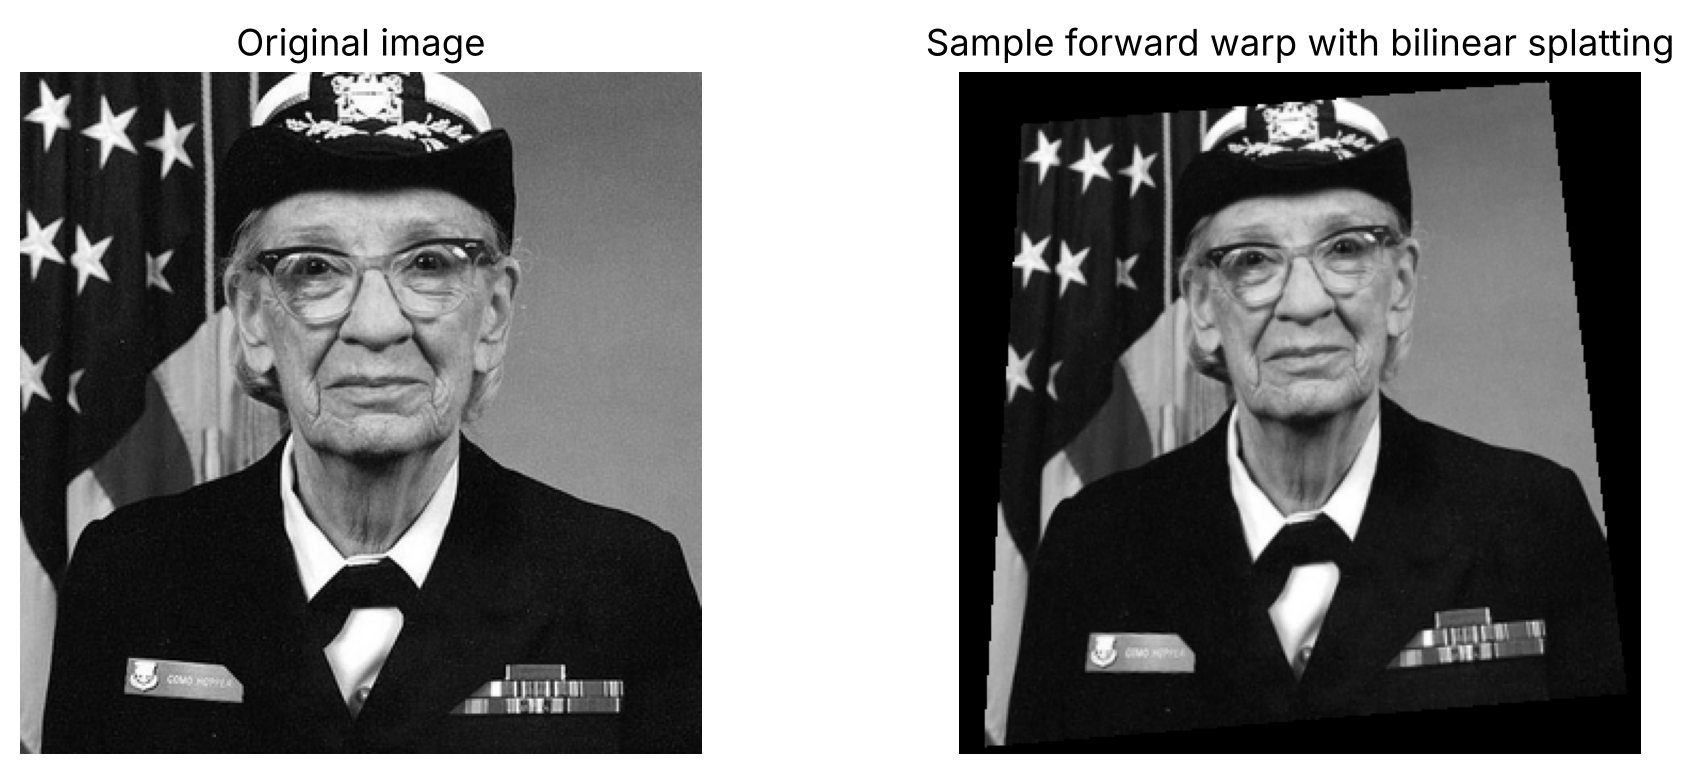

In [6]:
# SAMPLE CODE: warp a rectangular image into a projectively distorted quadrilateral.
h, w = image.shape
sample_source = np.array([[0, 0], [w-1, 0], [w-1, h-1], [0, h-1]], dtype=float)
sample_destination = np.array([[30, 25], [w-45, 5], [w-8, h-30], [12, h-5]], dtype=float)

H_sample = estimate_homography_dlt(sample_source, sample_destination)
sample_warped, sample_weights = forward_warp_homography(
    image, H_sample, output_shape=image.shape
)

print('Sample homography H:\n', np.round(H_sample, 4))
print('Mapped corners:\n', np.round(transform_points_homogeneous(sample_source, H_sample), 1))
print('Covered output pixels:', np.count_nonzero(sample_weights), '/', sample_weights.size)
show_images([image, sample_warped],
            ['Original image', 'Sample forward warp with bilinear splatting'])

### 2.3 TODO: Estimate and apply a new homography

Student homography H:
 [[ 7.473e-01 -9.350e-02  4.500e+01]
 [ 7.230e-02  8.413e-01  1.000e+01]
 [-2.000e-04  0.000e+00  1.000e+00]]
Mapped corners:
 [[ 45.  10.]
 [300.  35.]
 [265. 315.]
 [ 15. 275.]]
Original center: [160. 160.]
Mapped center: [152.92 159.62]
Covered output pixels: 70990 / 102400


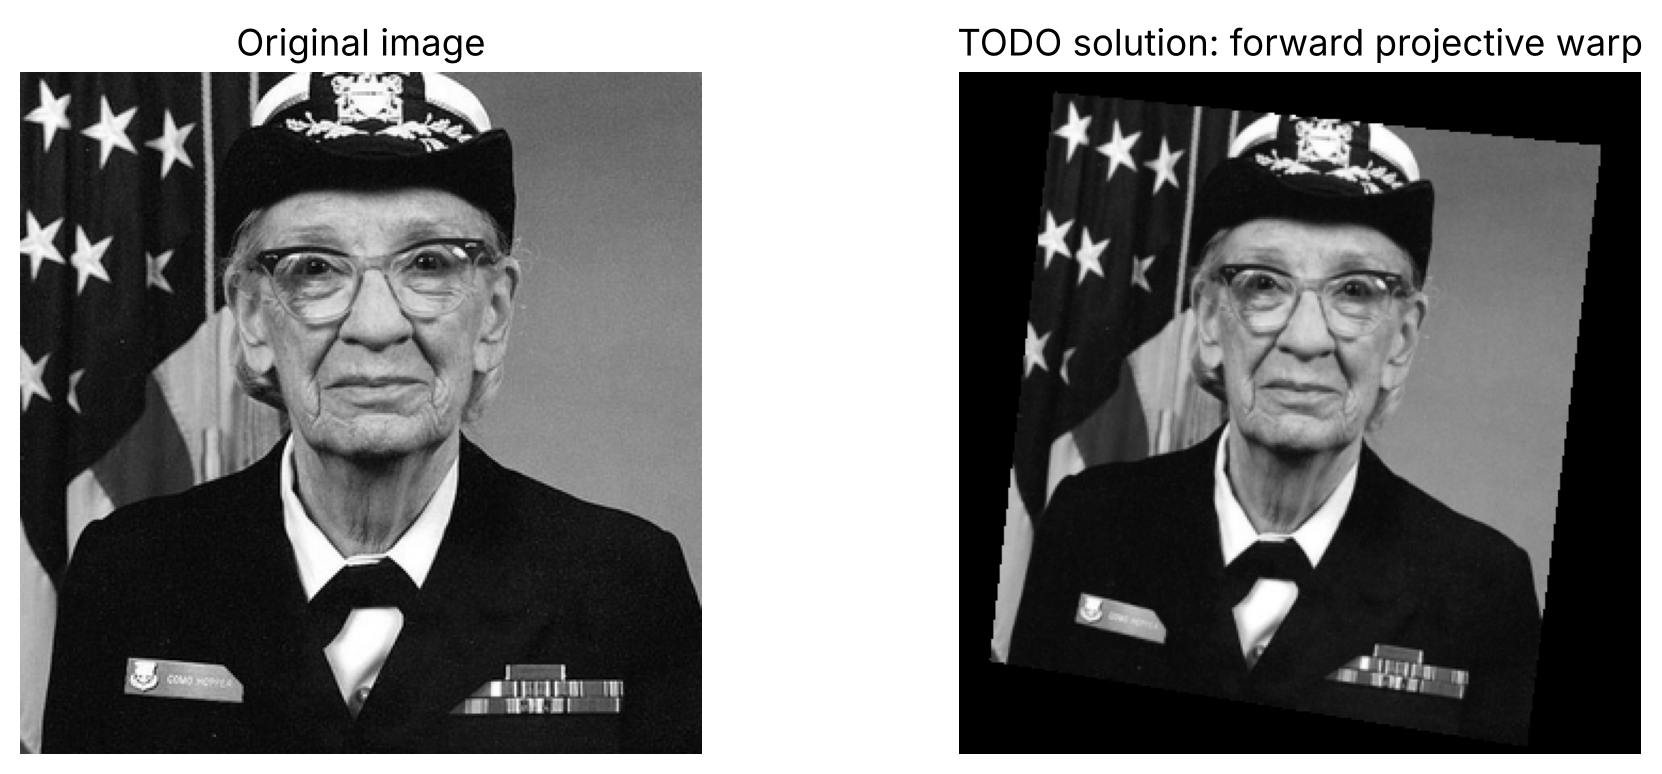

In [7]:
# TODO 1: Use the four original corners in sample_source and define destination corners:
# [[45, 10], [w-20, 35], [w-55, h-5], [15, h-45]].
student_destination = np.array([[45, 10], [w-20, 35], [w-55, h-5], [15, h-45]], dtype=float)

# TODO 2: Estimate student_H with estimate_homography_dlt().
student_H = estimate_homography_dlt(sample_source, student_destination)

# Map the center point [[w/2, h/2]] using homogeneous coordinates.
student_center = np.array([[w/2, h/2]], dtype=float)
student_center_mapped = transform_points_homogeneous(student_center, student_H)

# TODO 3: Forward-warp the image using bilinear splatting, then display the result.
student_warped, student_weights = forward_warp_homography(
    image, student_H, output_shape=image.shape
)

# Your display and print code here.
print('Student homography H:\n', np.round(student_H, 4))
print('Mapped corners:\n', np.round(transform_points_homogeneous(sample_source, student_H), 1))
print('Original center:', np.round(student_center[0], 2))
print('Mapped center:', np.round(student_center_mapped[0], 2))
print('Covered output pixels:', np.count_nonzero(student_weights), '/', student_weights.size)
show_images([image, student_warped],
            ['Original image', 'TODO solution: forward projective warp'])